# Phase 3 — Detailed Validation-Governed Feature Engineering

Features and preprocessing are developed on training data and compared on the locked validation partition. The validation set is not loaded.

## 1. Imports and source

In [1]:
from pathlib import Path
import json, warnings, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns",50); pd.set_option("display.float_format",lambda x:f"{x:,.4f}")
sns.set_theme(style="whitegrid",context="notebook")
BLUE,ORANGE,INK="#4C78A8","#F58518","#263238"
root=Path.cwd()
if not (root/"data/raw/ai4i2020.csv").exists(): root=root.parent
raw=pd.read_csv(root/"data/raw/ai4i2020.csv")
TARGET="Machine failure"; IDS=["UDI","Product ID"]; LEAK=["TWF","HDF","PWF","OSF","RNF"]
BASE=["Type","Air temperature [K]","Process temperature [K]","Rotational speed [rpm]","Torque [Nm]","Tool wear [min]"]
print(raw.shape)
from sklearn.model_selection import train_test_split,StratifiedKFold,cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

(10000, 14)


## 2. Explicit feature policy

In [2]:
policy=pd.DataFrame({'group':['identifiers','target','target-derived leakage','eligible raw'],'columns':[IDS,[TARGET],LEAK,BASE]}); display(policy); assert not set(IDS+LEAK+[TARGET])&set(BASE)

,group,columns
0,identifiers,"[UDI, Product ID]"
1,target,[Machine failure]
2,target-derived leakage,"[TWF, HDF, PWF, OSF, RNF]"
3,eligible raw,"[Type, Air temperature [K], Process temperatur..."


## 3. Stratified split before learned transforms

In [3]:
train_raw = pd.read_csv(root / "data" / "governed" / "train.csv")
test_raw = pd.read_csv(root / "data" / "governed" / "validation.csv")
target_column = TARGET
ytr = train_raw[target_column]
yte = test_raw[target_column]
display(pd.DataFrame({
    "partition": ["Train", "Validation"],
    "rows": [len(train_raw), len(test_raw)],
    "failures": [int(ytr.sum()), int(yte.sum())],
    "failure_rate_pct": [100*ytr.mean(), 100*yte.mean()],
}))

,partition,rows,failures,failure_rate_pct
0,Train,7000,237,3.3857
1,Validation,1500,51,3.4000


## 4. Deterministic feature function

In [4]:
def engineer(df):
 out=df[BASE].copy()
 out['Temperature difference [K]']=out['Process temperature [K]']-out['Air temperature [K]']
 out['Mechanical power [W]']=2*np.pi*out['Rotational speed [rpm]']*out['Torque [Nm]']/60
 out['Torque × tool wear']=out['Torque [Nm]']*out['Tool wear [min]']
 out['Power × tool wear']=out['Mechanical power [W]']*out['Tool wear [min]']
 out['Temperature ratio']=out['Process temperature [K]']/out['Air temperature [K]']
 return out
Xtr,Xte=engineer(train_raw),engineer(test_raw); ytr,yte=train_raw[TARGET],test_raw[TARGET]; display(Xtr.head())

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperature difference [K],Mechanical power [W],Torque × tool wear,Power × tool wear,Temperature ratio
0,L,295.5000,305.9000,1542,36.2000,12,10.4000,"5,845.4986",434.4000,"70,145.9834",1.0352
1,M,300.3000,311.9000,1677,30.8000,48,11.6000,"5,408.9429","1,478.4000","259,629.2594",1.0386
2,L,298.6000,309.7000,1429,45.8000,113,11.1000,"6,853.7195","5,175.4000","774,470.3009",1.0372
3,M,298.7000,309.7000,1868,23.8000,118,11.0000,"4,655.6728","2,808.4000","549,369.3858",1.0368
4,M,300.7000,310.6000,2006,19.1000,102,9.9000,"4,012.2955","1,948.2000","409,254.1440",1.0329


## 5. Feature provenance manifest

In [5]:
manifest=pd.DataFrame([
('Temperature difference [K]','Process temperature - air temperature','thermal load proxy'),
('Mechanical power [W]','2π × rpm × torque / 60','mechanical load'),
('Torque × tool wear','torque × tool wear','load/wear interaction'),
('Power × tool wear','power × tool wear','energy/wear interaction'),
('Temperature ratio','process / air temperature','relative thermal state')],columns=['feature','formula','purpose']); display(manifest)

,feature,formula,purpose
0,Temperature difference [K],Process temperature - air temperature,thermal load proxy
1,Mechanical power [W],2π × rpm × torque / 60,mechanical load
2,Torque × tool wear,torque × tool wear,load/wear interaction
3,Power × tool wear,power × tool wear,energy/wear interaction
4,Temperature ratio,process / air temperature,relative thermal state


## 6. Train/validation schema and finite-value validation

In [6]:
assert Xtr.columns.tolist()==Xte.columns.tolist(); assert np.isfinite(Xtr.select_dtypes('number')).all().all(); assert np.isfinite(Xte.select_dtypes('number')).all().all(); print(Xtr.shape,Xte.shape); display(Xtr.dtypes.to_frame('dtype'))

(7000, 11) (1500, 11)


,dtype
Type,str
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Temperature difference [K],float64
Mechanical power [W],float64
Torque × tool wear,float64
Power × tool wear,float64


## 7. Leakage audit after engineering

In [7]:
forbidden=set(IDS+LEAK+[TARGET]); overlap=forbidden&set(Xtr); print('Forbidden overlap',overlap); assert not overlap; print('PASS')

Forbidden overlap set()
PASS


## 8. Engineered-feature descriptive checks

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],"7,000.0000",300.0365,2.0013,295.3000,298.4000,300.1000,301.5250,304.4000
Process temperature [K],"7,000.0000",310.0255,1.4832,305.7000,308.8000,310.1000,311.1000,313.8000
Rotational speed [rpm],"7,000.0000","1,538.3483",177.4437,"1,181.0000","1,424.0000","1,502.0000","1,612.0000","2,874.0000"
Torque [Nm],"7,000.0000",40.0216,9.9662,4.2000,33.2000,40.1000,46.8000,75.4000
Tool wear [min],"7,000.0000",108.5786,63.7326,0.0000,54.0000,108.0000,164.0000,253.0000
Temperature difference [K],"7,000.0000",9.9890,1.0071,7.6000,9.2000,9.8000,11.0000,12.1000
Mechanical power [W],"7,000.0000","6,285.0461","1,069.1071","1,264.0512","5,557.2339","6,268.9748","7,014.4800","10,469.9230"
Torque × tool wear,"7,000.0000","4,346.4587","2,847.9451",0.0000,"2,005.8250","4,038.9000","6,320.2500","16,497.0000"
Power × tool wear,"7,000.0000","682,536.6050","423,197.4405",0.0000,"327,350.7187","660,027.7721","1,001,390.6720","2,180,182.9919"
Temperature ratio,"7,000.0000",1.0333,0.0035,1.0251,1.0306,1.0328,1.0367,1.0407


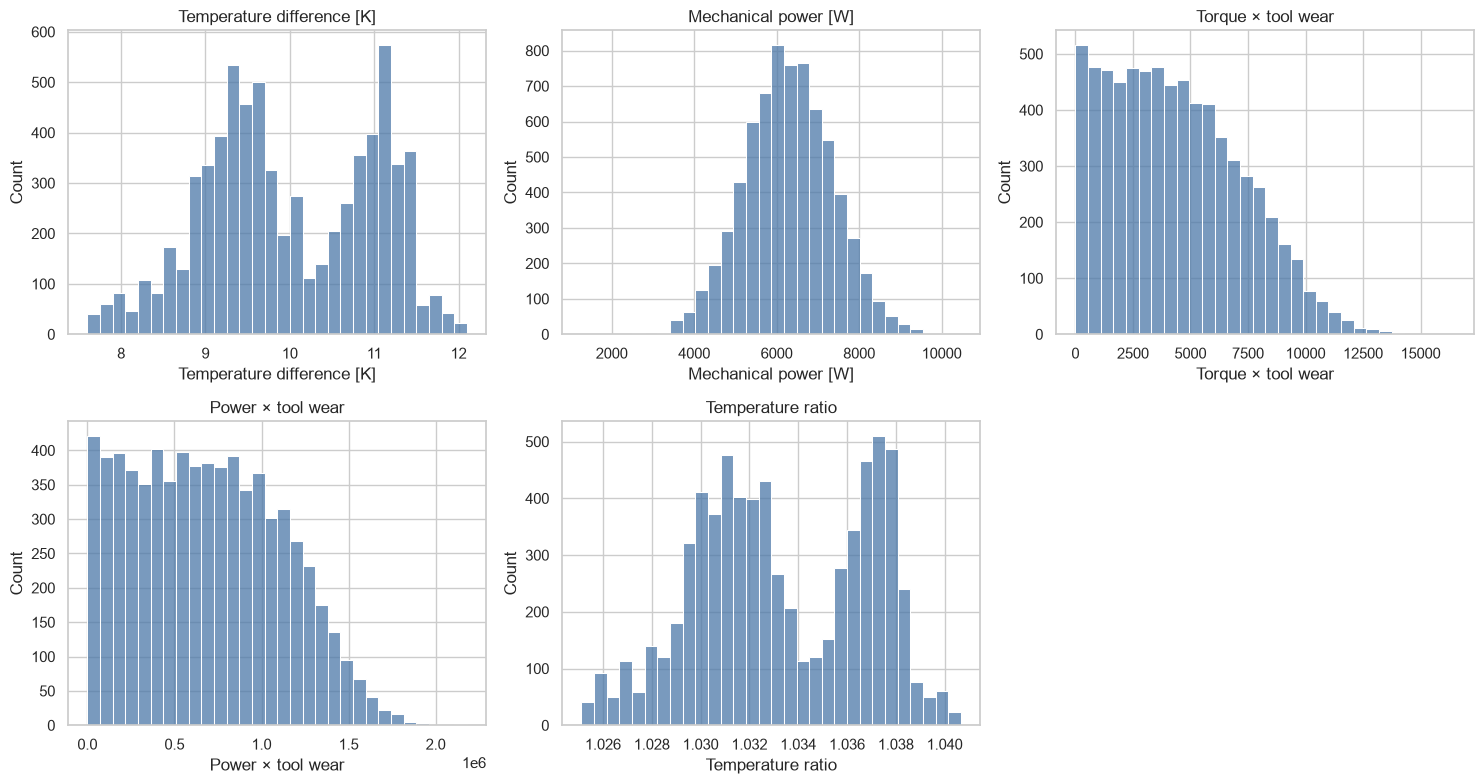

In [8]:
display(Xtr.describe().T); fig,axs=plt.subplots(2,3,figsize=(15,8)); 
for c,ax in zip(Xtr.columns[-5:],axs.flat): sns.histplot(Xtr[c],bins=30,color=BLUE,ax=ax); ax.set_title(c)
axs.flat[-1].axis('off'); plt.tight_layout(); plt.show()

## 9. Redundancy and correlation review

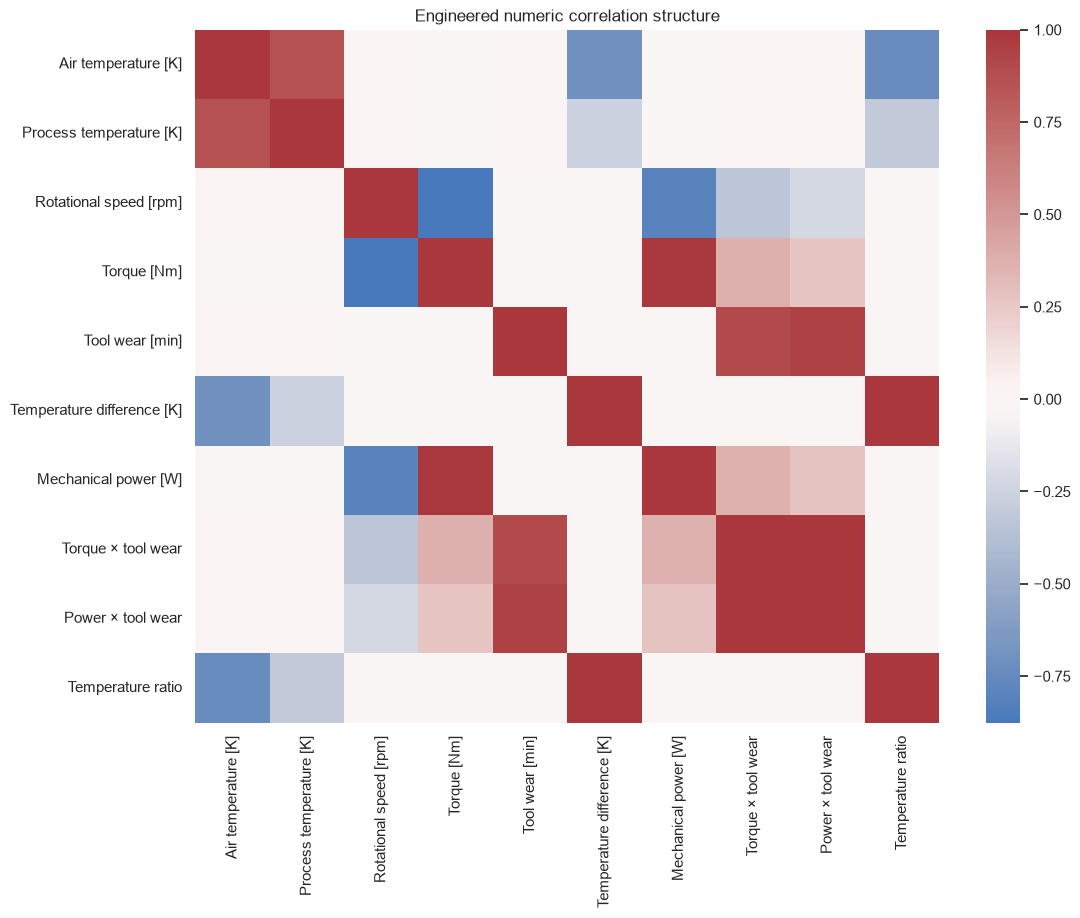

In [9]:
plt.figure(figsize=(12,9)); sns.heatmap(Xtr.select_dtypes('number').corr(),cmap='vlag',center=0); plt.title('Engineered numeric correlation structure'); plt.show()

## 10. Preprocessing definition

In [10]:
cat=['Type']; num=[c for c in Xtr if c not in cat]; pre=ColumnTransformer([('num',StandardScaler(),num),('cat',OneHotEncoder(handle_unknown='ignore'),cat)]); print('numeric',num); print('categorical',cat)

numeric ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temperature difference [K]', 'Mechanical power [W]', 'Torque × tool wear', 'Power × tool wear', 'Temperature ratio']
categorical ['Type']


## 11. Fit preprocessing on train only

In [11]:
Xt=pre.fit_transform(Xtr); Xv=pre.transform(Xte); names=pre.get_feature_names_out(); print(Xt.shape,Xv.shape); display(pd.DataFrame(Xt[:5],columns=names))

(7000, 13) (1500, 13)


,num__Air temperature [K],num__Process temperature [K],num__Rotational speed [rpm],num__Torque [Nm],num__Tool wear [min],num__Temperature difference [K],num__Mechanical power [W],num__Torque × tool wear,num__Power × tool wear,num__Temperature ratio,cat__Type_H,cat__Type_L,cat__Type_M
0,-2.2670,-2.7818,0.0206,-0.3835,-1.5155,0.4081,-0.4112,-1.3737,-1.4472,0.5367,0.0000,1.0000,0.0000
1,0.1317,1.2639,0.7814,-0.9253,-0.9506,1.5997,-0.8195,-1.0071,-0.9994,1.5144,0.0000,0.0000,1.0000
2,-0.7178,-0.2195,-0.6163,0.5798,0.0694,1.1032,0.5320,0.2911,0.2173,1.1002,0.0000,1.0000,0.0000
3,-0.6679,-0.2195,1.8579,-1.6278,0.1478,1.0039,-1.5242,-0.5401,-0.3147,1.0013,0.0000,0.0000,1.0000
4,0.3316,0.3873,2.6357,-2.0994,-0.1032,-0.0884,-2.1260,-0.8422,-0.6458,-0.1101,0.0000,0.0000,1.0000


## 12. Unknown-category behavior

In [12]:
probe=Xte.head(1).copy(); probe['Type']='UNKNOWN'; print(pre.transform(probe).shape,'unknown category safely ignored')

(1, 13) unknown category safely ignored


## 13. Raw versus engineered feature-set experiment

In [13]:
cv=StratifiedKFold(5,shuffle=True,random_state=42)
sets={'raw':BASE,'engineered':Xtr.columns.tolist()}; rows=[]
for label,cols in sets.items():
 cats=['Type']; nums=[c for c in cols if c!='Type']; p=Pipeline([('pre',ColumnTransformer([('n',StandardScaler(),nums),('c',OneHotEncoder(handle_unknown='ignore'),cats)])),('m',LogisticRegression(class_weight='balanced',max_iter=2000))])
 s=cross_val_score(p,train_raw[BASE] if label=='raw' else Xtr,ytr,cv=cv,scoring='average_precision'); rows.append((label,s.mean(),s.std()))
display(pd.DataFrame(rows,columns=['feature_set','mean_pr_auc','std_pr_auc']))

,feature_set,mean_pr_auc,std_pr_auc
0,raw,0.4319,0.0310
1,engineered,0.4478,0.0432


## 14. Tree-model feature-set experiment

In [14]:
rows=[]
for label,frame in [('raw',train_raw[BASE]),('engineered',Xtr)]:
 cols=frame.columns; p=Pipeline([('pre',ColumnTransformer([('n','passthrough',[c for c in cols if c!='Type']),('c',OneHotEncoder(handle_unknown='ignore'),['Type'])])),('m',RandomForestClassifier(n_estimators=250,min_samples_leaf=2,class_weight='balanced_subsample',random_state=42,n_jobs=1))]); s=cross_val_score(p,frame,ytr,cv=cv,scoring='average_precision'); rows.append((label,s.mean(),s.std()))
display(pd.DataFrame(rows,columns=['feature_set','mean_pr_auc','std_pr_auc']))

,feature_set,mean_pr_auc,std_pr_auc
0,raw,0.7207,0.0335
1,engineered,0.8831,0.0435


## 15. Save processed splits

In [15]:
out=root/'data/processed'; out.mkdir(parents=True,exist_ok=True); tr=Xtr.copy(); tr[TARGET]=ytr.values; te=Xte.copy(); te[TARGET]=yte.values; tr.to_csv(out/'train_engineered.csv',index=False); te.to_csv(out/'test_engineered.csv',index=False); manifest.to_csv(out/'feature_manifest.csv',index=False); print(out.resolve())

data/processed


## 16. Save split and feature metadata

In [16]:
meta={'random_state':42,'test_size':.2,'stratified':True,'target':TARGET,'features':Xtr.columns.tolist(),'identifiers_excluded':IDS,'leakage_excluded':LEAK,'train_rows':len(Xtr),'test_rows':len(Xte)}; (out/'split_metadata.json').write_text(json.dumps(meta,indent=2)); display(meta)

{'random_state': 42,
 'test_size': 0.2,
 'stratified': True,
 'target': 'Machine failure',
 'features': ['Type',
  'Air temperature [K]',
  'Process temperature [K]',
  'Rotational speed [rpm]',
  'Torque [Nm]',
  'Tool wear [min]',
  'Temperature difference [K]',
  'Mechanical power [W]',
  'Torque × tool wear',
  'Power × tool wear',
  'Temperature ratio'],
 'identifiers_excluded': ['UDI', 'Product ID'],
 'leakage_excluded': ['TWF', 'HDF', 'PWF', 'OSF', 'RNF'],
 'train_rows': 7000,
 'test_rows': 1500}

## 17. Final QA and handoff

In [17]:
assert pd.read_csv(out/'train_engineered.csv').shape==tr.shape; assert pd.read_csv(out/'test_engineered.csv').shape==te.shape; print('Phase 3 PASS: processed data and manifests are ready for Phase 4.')

Phase 3 PASS: processed data and manifests are ready for Phase 4.
